<a href="https://colab.research.google.com/github/onszayani/MiniProjet2A-EventReservation-OnsZayani/blob/main/notebooks/e3_entrainement.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# from google.colab import drive
# drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# !unzip -q /content/drive/MyDrive/fatigue_project/mrl-eye-dataset.zip -d /content/data

In [3]:
import os, json, random
import numpy as np
import pandas as pd

base = '/content/data/mrleyedataset'
classes = {'Close-Eyes': 0, 'Open-Eyes': 1}   # 0 = fermé, 1 = ouvert

with open('/content/drive/MyDrive/fatigue_project/splits.json') as f:
    splits = json.load(f)
groupe_de = {s: g for g in ['train', 'val', 'test'] for s in splits[g]}

lignes = []
for c, label in classes.items():
    for fich in os.listdir(f'{base}/{c}'):
        sujet = fich.split('_')[0]
        lignes.append({'chemin': f'{base}/{c}/{fich}', 'label': label,
                       'sujet': sujet, 'groupe': groupe_de[sujet]})
df = pd.DataFrame(lignes)
print(df.groupby(['groupe', 'label']).size().unstack())

label       0      1
groupe              
test     6274   6053
train   28402  30707
val      7270   6192


In [4]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

TAILLE = 96
MOY, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

transf_train = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((TAILLE, TAILLE)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.4, contrast=0.4),
    transforms.RandomApply([transforms.GaussianBlur(3)], p=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MOY, STD),
])
transf_eval = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((TAILLE, TAILLE)),
    transforms.ToTensor(),
    transforms.Normalize(MOY, STD),
])

class EyeDataset(Dataset):
    def __init__(self, tableau, transform):
        self.t = tableau.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.t)
    def __getitem__(self, i):
        ligne = self.t.iloc[i]
        img = Image.open(ligne['chemin'])
        return self.transform(img), torch.tensor(ligne['label'], dtype=torch.float32)

ds_train = EyeDataset(df[df.groupe == 'train'], transf_train)
ds_val   = EyeDataset(df[df.groupe == 'val'],   transf_eval)
ds_test  = EyeDataset(df[df.groupe == 'test'],  transf_eval)

dl_train = DataLoader(ds_train, batch_size=64, shuffle=True,  num_workers=2)
dl_val   = DataLoader(ds_val,   batch_size=64, shuffle=False, num_workers=2)
dl_test  = DataLoader(ds_test,  batch_size=64, shuffle=False, num_workers=2)

print(len(ds_train), len(ds_val), len(ds_test))

59109 13462 12327


graine aléatoire et modèle

In [5]:
import torch.nn as nn
from torchvision import models

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Appareil :", device)

model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
model.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(model.last_channel, 1))
model = model.to(device)

# Vérification des dimensions (pour ton schéma d'architecture)
x, y = next(iter(dl_train))
with torch.no_grad():
    f = model.features(x.to(device))
    print("Entrée          :", x.shape)
    print("Après features  :", f.shape)
    print("Après pooling   :", f.mean([2, 3]).shape)
    print("Sortie (logit)  :", model(x.to(device)).shape)

Appareil : cuda
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 199MB/s]


Entrée          : torch.Size([64, 3, 96, 96])
Après features  : torch.Size([64, 1280, 3, 3])
Après pooling   : torch.Size([64, 1280])
Sortie (logit)  : torch.Size([64, 1])


fonctions d'évaluation et d'entraînement

In [6]:
from sklearn.metrics import f1_score

criterion = nn.BCEWithLogitsLoss()
historique = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}
CHEMIN_MODELE = '/content/drive/MyDrive/fatigue_project/meilleur_modele.pt'
meilleure_val = float('inf')

def evaluer(dl):
    model.eval()
    pertes, preds, labs = 0, [], []
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb).squeeze(1)
            pertes += criterion(out, yb).item() * len(yb)
            preds += (torch.sigmoid(out) > 0.5).float().cpu().tolist()
            labs += yb.cpu().tolist()
    preds, labs = np.array(preds), np.array(labs)
    return pertes / len(labs), (preds == labs).mean(), f1_score(labs, preds)

def entrainer(epoques, lr, patience=2):
    global meilleure_val
    opt = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    sans_progres = 0
    for ep in range(epoques):
        model.train()
        total = 0
        for xb, yb in dl_train:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            perte = criterion(model(xb).squeeze(1), yb)
            perte.backward()
            opt.step()
            total += perte.item() * len(yb)
        tl = total / len(ds_train)
        vl, va, vf = evaluer(dl_val)
        for k, v in zip(historique, [tl, vl, va, vf]):
            historique[k].append(v)
        print(f"Époque {ep+1}/{epoques} | train_loss {tl:.4f} | val_loss {vl:.4f} | val_acc {va:.4f} | val_F1 {vf:.4f}")
        if vl < meilleure_val:
            meilleure_val = vl
            torch.save(model.state_dict(), CHEMIN_MODELE)
            sans_progres = 0
        else:
            sans_progres += 1
            if sans_progres >= patience:
                print("Arrêt anticipé (la validation ne s'améliore plus).")
                break

phase 1 (on entraîne seulement la nouvelle couche)

In [8]:
for p in model.features.parameters():
    p.requires_grad = False
entrainer(epoques=3, lr=1e-3)

Époque 1/3 | train_loss 0.2521 | val_loss 0.2821 | val_acc 0.8897 | val_F1 0.8810
Époque 2/3 | train_loss 0.2530 | val_loss 0.2984 | val_acc 0.8940 | val_F1 0.8907
Époque 3/3 | train_loss 0.2554 | val_loss 0.3223 | val_acc 0.8752 | val_F1 0.8731
Arrêt anticipé (la validation ne s'améliore plus).


phase 2 (fine-tuning de tout le réseau)

In [9]:
for p in model.parameters():
    p.requires_grad = True
entrainer(epoques=5, lr=1e-4)

Époque 1/5 | train_loss 0.0668 | val_loss 0.0461 | val_acc 0.9891 | val_F1 0.9882
Époque 2/5 | train_loss 0.0401 | val_loss 0.0269 | val_acc 0.9941 | val_F1 0.9936
Époque 3/5 | train_loss 0.0333 | val_loss 0.0369 | val_acc 0.9892 | val_F1 0.9883
Époque 4/5 | train_loss 0.0292 | val_loss 0.0584 | val_acc 0.9817 | val_F1 0.9805
Arrêt anticipé (la validation ne s'améliore plus).


courbes d'apprentissage

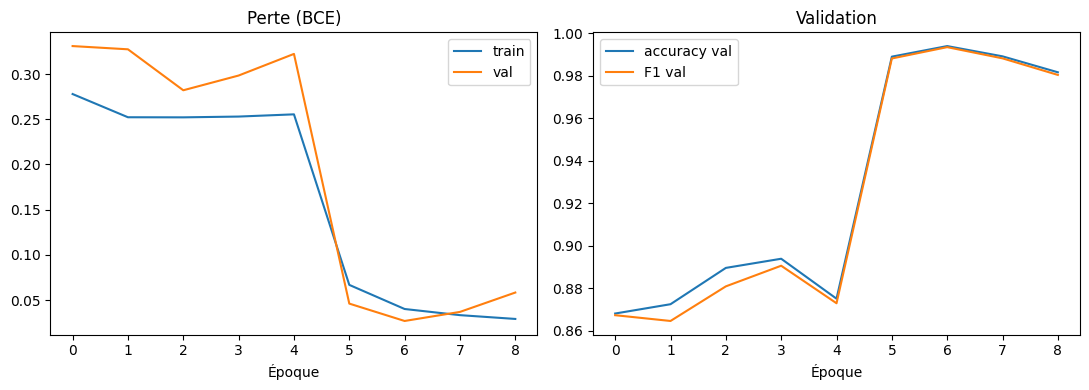

In [10]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(historique['train_loss'], label='train'); ax[0].plot(historique['val_loss'], label='val')
ax[0].set_title('Perte (BCE)'); ax[0].set_xlabel('Époque'); ax[0].legend()
ax[1].plot(historique['val_acc'], label='accuracy val'); ax[1].plot(historique['val_f1'], label='F1 val')
ax[1].set_title('Validation'); ax[1].set_xlabel('Époque'); ax[1].legend()
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/fatigue_project/figures/courbes_entrainement.png', dpi=150, bbox_inches='tight')
plt.show()

les métriques sur le test

Accuracy          : 0.98
F1 (classe ouvert): 0.9799
Précision ouvert  : 0.9648
Rappel ouvert     : 0.9955
Rappel FERMÉ      : 0.9649
AUC ROC           : 0.9984


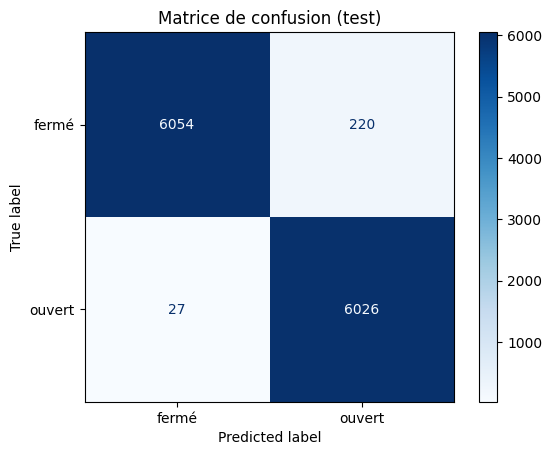

In [11]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_auc_score, ConfusionMatrixDisplay)

model.load_state_dict(torch.load(CHEMIN_MODELE, map_location=device))
model.eval()

probas, labs = [], []
with torch.no_grad():
    for xb, yb in dl_test:
        p = torch.sigmoid(model(xb.to(device)).squeeze(1)).cpu()
        probas += p.tolist(); labs += yb.tolist()
probas, labs = np.array(probas), np.array(labs)
preds = (probas > 0.5).astype(int)

print("Accuracy          :", round(accuracy_score(labs, preds), 4))
print("F1 (classe ouvert):", round(f1_score(labs, preds), 4))
print("Précision ouvert  :", round(precision_score(labs, preds), 4))
print("Rappel ouvert     :", round(recall_score(labs, preds), 4))
print("Rappel FERMÉ      :", round(recall_score(labs, preds, pos_label=0), 4))
print("AUC ROC           :", round(roc_auc_score(labs, probas), 4))

cm = confusion_matrix(labs, preds)
ConfusionMatrixDisplay(cm, display_labels=['fermé', 'ouvert']).plot(cmap='Blues')
plt.title("Matrice de confusion (test)")
plt.savefig('/content/drive/MyDrive/fatigue_project/figures/matrice_confusion_test.png', dpi=150, bbox_inches='tight')
plt.show()

où le modèle se trompe-t-il ?

In [12]:
t = ds_test.t.copy()
t['pred'], t['proba'] = preds, probas
t['ok'] = (t['pred'] == t['label'])
t['lunettes'] = t['chemin'].map(lambda c: os.path.basename(c).split('_')[3])

print("Accuracy selon les lunettes (0 = sans, 1 = avec) :")
print(t.groupby('lunettes')['ok'].mean().round(4))
print("\nAccuracy par personne :")
print(t.groupby('sujet')['ok'].agg(['size', 'mean']).round(4))

Accuracy selon les lunettes (0 = sans, 1 = avec) :
lunettes
0    0.9868
1    0.9640
Name: ok, dtype: float64

Accuracy par personne :
       size    mean
sujet              
s0002  1114  0.9982
s0009   387  0.8992
s0012  8728  0.9884
s0024   752  0.9402
s0027   665  0.9489
s0033   681  0.9618


exemples d'erreurs

Nombre d'erreurs : 247 sur 12327


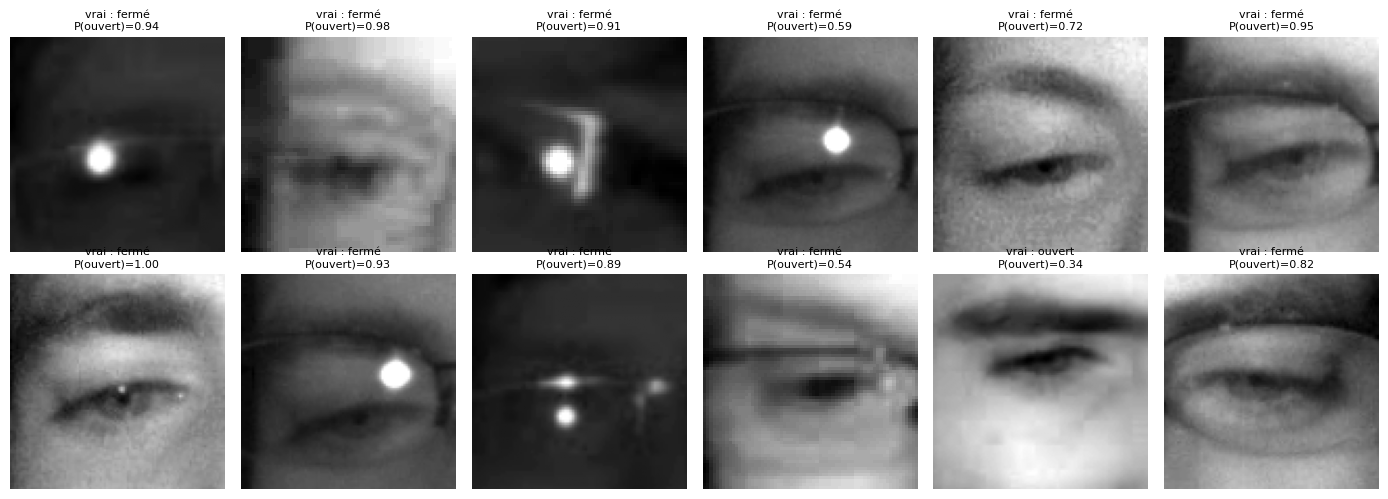

In [13]:
erreurs = t[~t['ok']]
print("Nombre d'erreurs :", len(erreurs), "sur", len(t))
echantillon = erreurs.sample(min(12, len(erreurs)), random_state=0)

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ax, (_, r) in zip(axes.flat, echantillon.iterrows()):
    ax.imshow(Image.open(r['chemin']), cmap='gray')
    vrai = 'ouvert' if r['label'] == 1 else 'fermé'
    ax.set_title(f"vrai : {vrai}\nP(ouvert)={r['proba']:.2f}", fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/fatigue_project/figures/erreurs_test.png', dpi=150, bbox_inches='tight')
plt.show()